<a href="https://colab.research.google.com/github/miso88oup/image-caption-generator/blob/main/notebooks/02_feature_extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Caption Generator — Feature Extraction

Extract image features using three pretrained CNN encoders (ImageNet weights):

| Encoder | Input size | Feature size |
|---|---|---|
| VGG16 | 224 × 224 | 4096 (fc2) |
| ResNet50 | 224 × 224 | 2048 (avg pool) |
| InceptionV3 | 299 × 299 | 2048 (avg pool) |

## 1. Setup

In [1]:
import os
import json
import pickle

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from tensorflow.keras.models import Model
from tensorflow.keras.applications import vgg16, resnet50, inception_v3
from google.colab import drive

drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/image-caption-project'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
FEATURES_DIR = os.path.join(PROJECT_DIR, 'features')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
os.makedirs(FEATURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import kagglehub

DATASET_PATH = kagglehub.dataset_download('adityajn105/flickr8k')
IMAGE_DIR = os.path.join(DATASET_PATH, 'Images')

with open(os.path.join(DATA_DIR, 'splits.json')) as f:
    splits = json.load(f)

all_images = splits['train'] + splits['val'] + splits['test']
print('Images:', len(all_images))

Using Colab cache for faster access to the 'flickr8k' dataset.
Images: 8091


## 2. Encoders

In [3]:
def build_encoder(name):
    if name == 'vgg16':
        base = vgg16.VGG16(weights='imagenet')
        model = Model(base.input, base.get_layer('fc2').output)
        return model, vgg16.preprocess_input, (224, 224)

    if name == 'resnet50':
        model = resnet50.ResNet50(weights='imagenet', include_top=False, pooling='avg')
        return model, resnet50.preprocess_input, (224, 224)

    if name == 'inceptionv3':
        model = inception_v3.InceptionV3(weights='imagenet', include_top=False, pooling='avg')
        return model, inception_v3.preprocess_input, (299, 299)


def load_images(image_names, size, batch_size=64):
    paths = [os.path.join(IMAGE_DIR, n) for n in image_names]

    def load(path):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        return tf.image.resize(img, size)

    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

## 3. Extract Features

Features are saved to Drive as `{image_name: feature_vector}`. Encoders that are already done are skipped, so this cell can be re-run after a disconnect.

In [4]:
ENCODERS = ['vgg16', 'resnet50', 'inceptionv3']
BATCH_SIZE = 64

for name in ENCODERS:
    out_path = os.path.join(FEATURES_DIR, f'{name}.pkl')
    if os.path.exists(out_path):
        print(f'{name}: already extracted')
        continue

    model, preprocess, size = build_encoder(name)
    batches = load_images(all_images, size, BATCH_SIZE)
    n_batches = int(np.ceil(len(all_images) / BATCH_SIZE))

    feats = []
    for batch in tqdm(batches, total=n_batches, desc=name):
        feats.append(model.predict(preprocess(batch.numpy()), verbose=0))
    feats = np.concatenate(feats)

    with open(out_path, 'wb') as f:
        pickle.dump(dict(zip(all_images, feats)), f)

    print(f'{name}: {feats.shape}')
    del model
    tf.keras.backend.clear_session()

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


vgg16:   0%|          | 0/127 [00:00<?, ?it/s]

vgg16: (8091, 4096)
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


resnet50:   0%|          | 0/127 [00:00<?, ?it/s]

resnet50: (8091, 2048)
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


inceptionv3:   0%|          | 0/127 [00:00<?, ?it/s]

inceptionv3: (8091, 2048)


## 4. Check

In [5]:
features = {}
for name in ENCODERS:
    with open(os.path.join(FEATURES_DIR, f'{name}.pkl'), 'rb') as f:
        features[name] = pickle.load(f)
    print(f'{name}: {len(features[name])} images, feature size {len(next(iter(features[name].values())))}')

vgg16: 8091 images, feature size 4096
resnet50: 8091 images, feature size 2048
inceptionv3: 8091 images, feature size 2048


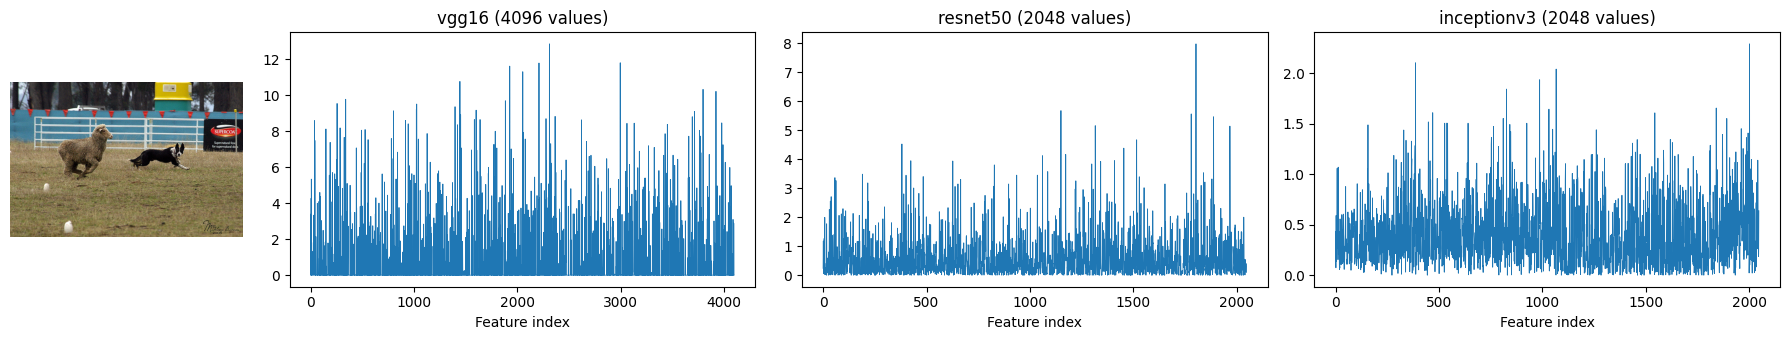

In [6]:
img = splits['train'][0]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), gridspec_kw={'width_ratios': [1, 2, 2, 2]})
axes[0].imshow(plt.imread(os.path.join(IMAGE_DIR, img)))
axes[0].axis('off')

for ax, name in zip(axes[1:], ENCODERS):
    vec = features[name][img]
    ax.plot(vec, linewidth=0.6)
    ax.set_title(f'{name} ({len(vec)} values)')
    ax.set_xlabel('Feature index')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'feature_vectors.png'), dpi=150, bbox_inches='tight')
plt.show()